   id                                           geometry
0   1  MULTIPOLYGON (((-58.02075 -13.84286, -58.00765...
1   2  MULTIPOLYGON (((-58.00734 -13.84936, -58.00642...
2   3  MULTIPOLYGON (((-57.97701 -13.85339, -57.97197...
3   4  MULTIPOLYGON (((-57.96708 -13.85803, -57.94429...
Index(['id', 'geometry'], dtype='str')


<Axes: >

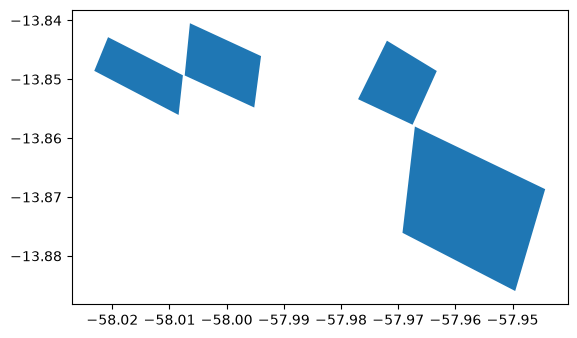

In [4]:
import geopandas as gpd

# Caminho do arquivo GeoJSON
caminho = "../data/polygon_data.geojson"

# Ler o arquivo
gdf = gpd.read_file(caminho)

# Visualizar os dados
print(gdf.head())

# Verificar as colunas
print(gdf.columns)


# Plotar os polígonos
gdf.plot()

In [ ]:

import geopandas as gpd
import pystac_client
import rasterio
import numpy as np
import matplotlib.pyplot as plt

from rasterio.mask import mask
from shapely.geometry import mapping
from shapely.ops import transform
from pyproj import Transformer


# --------------------------------------------------
# 1. CONFIGURAÇÕES
# --------------------------------------------------

# Datas no formato AAAA-MM-DD
data_inicio = "AAAA-MM-DD"  # Preencha a data inicial
data_fim = "AAAA-MM-DD"     # Preencha a data final

limite_nuvens = 20  # Percentual máximo de nuvens informado na cena

arquivo_saida = "sentinel2_id1_rgb.tif"


# --------------------------------------------------
# 2. SELECIONAR O POLÍGONO ID 1
# --------------------------------------------------

poligono = gdf.loc[gdf["id"] == 1].copy()

if poligono.empty:
    raise ValueError("Não foi encontrado o polígono com id = 1.")

# A geometria precisa estar em longitude/latitude para a busca STAC
poligono = poligono.to_crs("EPSG:4326")
geometria = poligono.geometry.union_all()


# --------------------------------------------------
# 3. CONECTAR À API STAC DA ELEMENT 84
# --------------------------------------------------

catalogo = pystac_client.Client.open(
    "https://earth-search.aws.element84.com/v1"
)

# Busca cenas que intersectam o polígono no período escolhido
busca = catalogo.search(
    collections=["sentinel-2-c1-l2a"],
    intersects=mapping(geometria),
    datetime=f"{data_inicio}/{data_fim}",
    query={"eo:cloud_cover": {"lt": limite_nuvens}}
)

cenas = list(busca.items())

if not cenas:
    raise ValueError(
        "Nenhuma cena encontrada. Tente ampliar o período "
        "ou aumentar o limite de nuvens."
    )

# Ordenar pela cobertura de nuvens da cena
cenas.sort(
    key=lambda cena: cena.properties.get("eo:cloud_cover", 100)
)

# Selecionar a cena com menor cobertura de nuvens
cena = cenas[0]

print("Cenas encontradas:", len(cenas))
print("ID da cena:", cena.id)
print("Data de aquisição:", cena.datetime)
print(
    "Cobertura de nuvens:",
    cena.properties.get("eo:cloud_cover"),
    "%"
)


# --------------------------------------------------
# 4. RECORTAR AS BANDAS RGB PELO POLÍGONO
# --------------------------------------------------

# Sentinel-2: vermelho, verde e azul (10 m)
bandas = ["red", "green", "blue"]
bandas_recortadas = []
transformacao_saida = None
perfil_saida = None

for nome_banda in bandas:

    # Obter o endereço do COG no catálogo
    url = cena.assets[nome_banda].href

    with rasterio.open(url) as src:

        # Transformar o polígono para o CRS da imagem
        conversor = Transformer.from_crs(
            "EPSG:4326",
            src.crs,
            always_xy=True
        )

        geometria_projetada = transform(
            conversor.transform,
            geometria
        )

        # Recortar a imagem
        imagem, transformacao = mask(
            src,
            [mapping(geometria_projetada)],
            crop=True,
            filled=True,
            nodata=0
        )

        bandas_recortadas.append(imagem[0])

        if nome_banda == "red":
            transformacao_saida = transformacao
            perfil_saida = src.profile.copy()

# Empilhar as bandas na ordem RGB
rgb = np.stack(bandas_recortadas, axis=0)

# Atualizar os metadados do GeoTIFF de saída
perfil_saida.update(
    driver="GTiff",
    height=rgb.shape[1],
    width=rgb.shape[2],
    count=3,
    transform=transformacao_saida,
    compress="deflate",
    nodata=0
)

# Salvar o resultado
with rasterio.open(arquivo_saida, "w", **perfil_saida) as dst:
    dst.write(rgb)

print(f"Imagem RGB salva em: {arquivo_saida}")


# --------------------------------------------------
# 5. VISUALIZAR A IMAGEM
# --------------------------------------------------

# Percentis para melhorar o contraste da visualização
rgb_visual = np.zeros(
    (rgb.shape[1], rgb.shape[2], 3),
    dtype=np.float32
)

for i in range(3):
    banda = rgb[i].astype(np.float32)
    valores_validos = banda[banda > 0]

    if valores_validos.size:
        minimo, maximo = np.percentile(
            valores_validos, [2, 98]
        )

        if maximo > minimo:
            rgb_visual[:, :, i] = np.clip(
                (banda - minimo) / (maximo - minimo),
                0, 1
            )

# Colocar pixels sem dados em preto
rgb_visual[np.all(rgb == 0, axis=0)] = 0

plt.figure(figsize=(10, 10))
plt.imshow(rgb_visual)
plt.title(f"Sentinel-2 RGB — Polígono ID 1\n{cena.datetime.date()}")
plt.axis("off")
plt.show()
